In [2]:
%pip install qiskit
%pip install matplotlib pylatexenc
%pip install qiskit_aer 


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from qiskit import *
from qiskit.visualization import plot_bloch_multivector, visualize_transition, plot_histogram
from qiskit_aer import Aer
from qiskit.quantum_info import Statevector

from qiskit.quantum_info import Operator
from qiskit.visualization import array_to_latex
from IPython.display import display


## Hadamard H-Gate

In [4]:
# initialize a single qubit quantum circuit
qc = QuantumCircuit(2)
# by default the qubit in the circuit will be in |0> state 
# represented as [1, 0] in the state vector
# in bloch sphere will be pointing to the north pole (z+ axis)

Initial state of the qubit before applying the gate


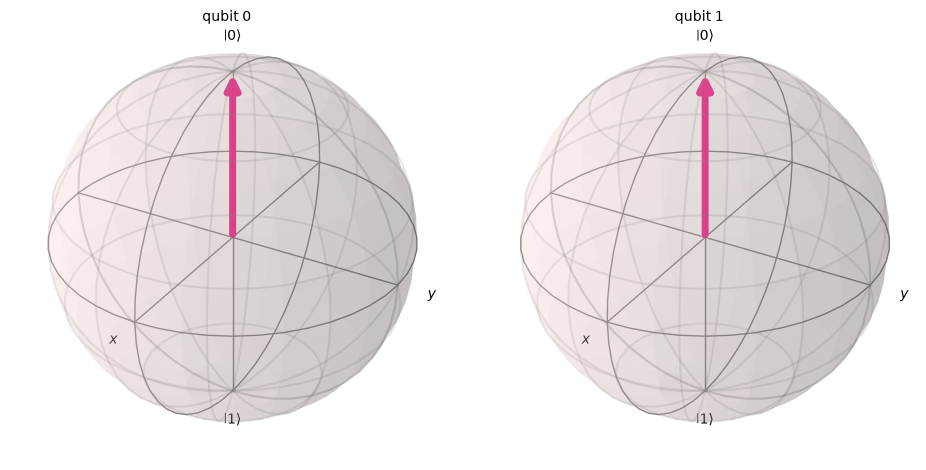

In [5]:
# to plot the qubit, get the current state 
initial_state = Statevector.from_instruction(qc)
print("Initial state of the qubit before applying the gate")
plot_bloch_multivector(initial_state)

In [6]:
# # un-comment the lines to make the |1> as initial state 
# initial_state = [0,1]
# qc.initialize(initial_state, 0)  

# # using the initial state, plot the bloch sphere
# print("Initial state of the qubit before applying the gate")
# plot_bloch_multivector(initial_state)

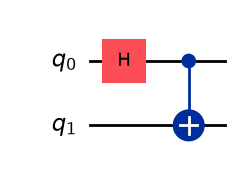

In [7]:
# apply the gate in the quantum circuit
qc.h(0)  # apply the gate to the first qubit (index = 0)
qc.cx(0,1)  # apply the gate to the first qubit (index = 0) and second qubit (index = 1)
qc.draw('mpl')  # using matplotlib library, draw the quantum circuit

In [8]:
backend = Aer.get_backend('unitary_simulator')
# output = execute(qc, backend).result().get_unitary()

compiled_circuit = transpile(qc, backend)
output = backend.run(compiled_circuit).result().get_unitary()


In [9]:
%pip install sympy  


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
# from qiskit_textbook.tools import array_to_latex
# array_to_latex(output, prefix="\\text{Circuit output = }")  

# Get the unitary matrix
output = Operator(qc).data

# Display the matrix in LaTeX
display(array_to_latex(output, prefix="\\text{Circuit output = }"))

<IPython.core.display.Latex object>

In [11]:
backend = Aer.get_backend('statevector_simulator')
compiled_circuit = transpile(qc, backend)
output = backend.run(compiled_circuit).result().get_statevector()

# output = Operator(qc).data

# Display the matrix in LaTeX
display(array_to_latex(output, prefix="\\text{Circuit output = }"))


<IPython.core.display.Latex object>

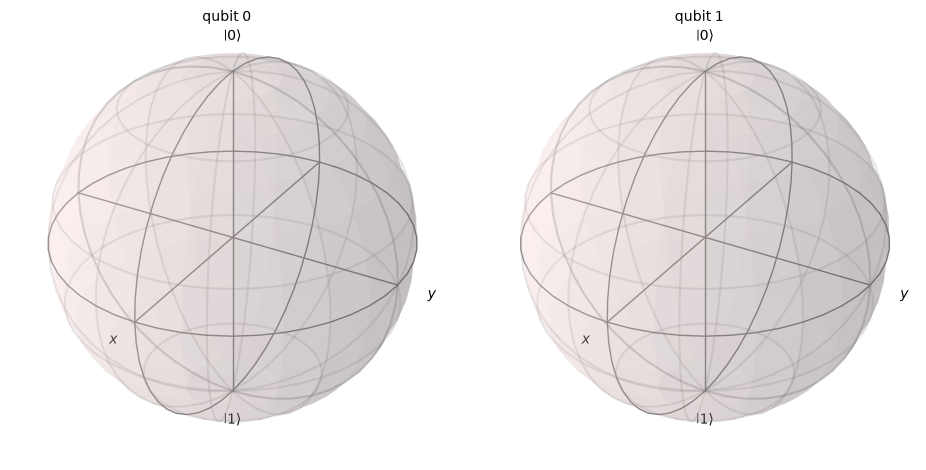

In [12]:
# get the current state of the qubit after applying the gate and plot it 
after_state = Statevector.from_instruction(qc)
plot_bloch_multivector(after_state)

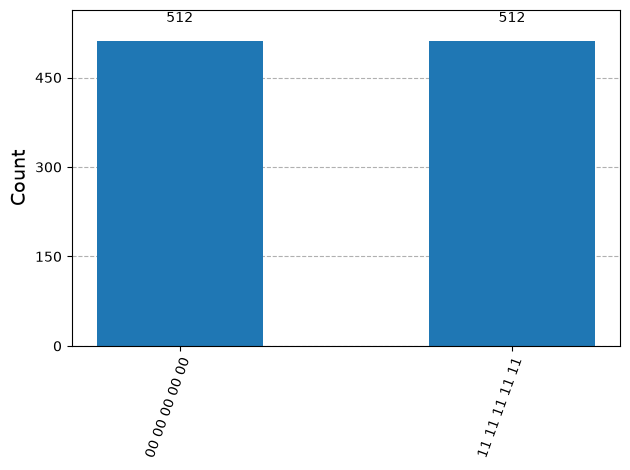

In [17]:
# add measurement to all the qubits
qc.measure_all()
# using QASM simulator, simulate a real quantum computer measurement  
backend = Aer.get_backend('qasm_simulator')
job = backend.run(qc, shots=1024)
counts = job.result().get_counts()
plot_histogram(counts)